# Física Computacional — Tarea-Práctica 5

**Métodos de diferenciación numérica**  
**Autores:** Sergio A. Alcalá Corona, Rodrigo Vega Vilchis y Joel Gómez Uribe  
**Grupo:** 8270  
**Semestre:** 2027-1  
**Fecha de entrega:** 4 de noviembre de 2026

---

## 1. Diferenciación numérica (valor 1 punto)

Crea una función $f(x)$ que devuelva

$$
f(x)=1+\frac{1}{2}\tanh(2x),
$$

luego usa diferencias centrales para calcular numéricamente la derivada de la función en el intervalo $-2\leq x\leq 2$.

Después, calcula la derivada analíticamente y haz una gráfica con tu resultado numérico y la respuesta analítica en el mismo gráfico. Puede resultar útil graficar la respuesta exacta como líneas y la numérica como puntos.

**Hint:** usa la función `tanh` del paquete `math`.


In [1]:
def diferencia_central(f,x,h):
    return (f(x+(h/2))-f(x-(h/2)))/h

In [2]:
import math as mt
def f1(x):
    return 1 + 1/2*mt.tanh(2*x)
def f2(x):
    return 1/(mt.cosh(2*x))**2

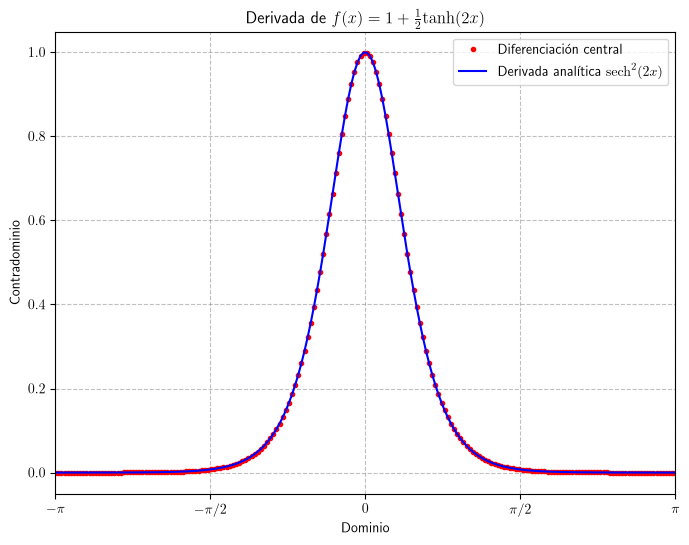

In [3]:
import matplotlib.pyplot as plt
import numpy as np

dominio = np.linspace(-np.pi,np.pi,200)
contradominio = [[diferencia_central(f1,dominio[i],0.001) for i in range(0,len(dominio))],[f2(dominio[i]) for i in range(0,len(dominio))]]


plt.rcParams["text.usetex"] = True


plt.figure(figsize=(8,6))

plt.title(r"Derivada de $f(x) = 1 + \frac{1}{2}\mathrm{tanh}(2x)$")
plt.plot(dominio,contradominio[0],"r.", label = "Diferenciación central")
plt.plot(dominio,contradominio[1],"b-", label = r"Derivada analítica $\mathrm{sech}^2(2x)$")
plt.xlabel("Dominio")
plt.ylabel("Contradominio")
plt.legend()
plt.xlim(-np.pi, np.pi)
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])
plt.grid(linestyle = "--", color = "gray", alpha = 0.5)

---
## 2. Campo eléctrico de una distribución de cargas (valor 3 puntos)

Supongamos que tenemos una distribución de cargas y queremos calcular el campo eléctrico resultante. Una forma de hacerlo es calcular primero el potencial eléctrico $\phi$ y luego tomar su gradiente.

Para una carga puntual $q$ en el origen, el potencial eléctrico a una distancia $r$ del origen es

$$
\phi=\frac{q}{4\pi\epsilon_0 r}
$$

y el campo eléctrico es

$$
\vec E=-\nabla\phi.
$$

### (a)

Suponiendo que tienes dos cargas, de $+1\,\mathrm C$ y $-1\,\mathrm C$ (respectivamente), separadas 10 cm. Calcula el potencial eléctrico resultante en un plano cuadrado de $1\,\mathrm m\times1\,\mathrm m$ que rodea las cargas y pasa a través de ellas.

Calcula el potencial en puntos espaciados a 1 cm en una cuadrícula y haz una visualización en la pantalla del potencial usando un gráfico de densidad.

---
El potencial eléctrico para esta configuración de cargas está dado por: 

$$\phi(x,y,z) = \frac{1}{4\pi\epsilon_0}\left(\frac{1}{\sqrt{x^2+y^2+(z-0.05)^2}}- \frac{1}{\sqrt{x^2+y^2+(z+0.05)^2}}\right)$$

Si hacemos $y=0$, entonces se puede observar que el potencial en ese plano está dado por: 

$$\phi(x,z) = \frac{1}{4\pi\epsilon_0}\left(\frac{1}{\sqrt{x^2+(z-0.05)^2}}- \frac{1}{\sqrt{x^2+(z+0.05)^2}}\right)$$

$$\therefore \boxed{\phi = \frac{1}{4\pi\epsilon_0}\left(\frac{1}{r_{1}}- \frac{1}{r_{2}}\right)}$$

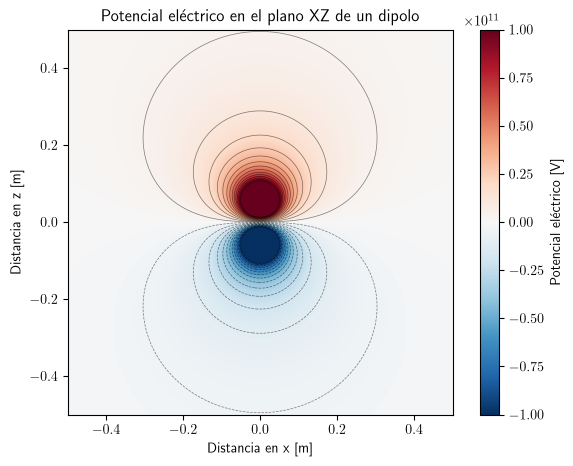

In [4]:
import numpy as np
import matplotlib.pyplot as plt

epsilon_0 = 8.8541878128e-12

x = np.linspace(-0.5,0.5,1000)
z = x
X,Z = np.meshgrid(x,z)

r1 = np.sqrt(X**2 + (Z-0.05)**2)
r2 = np.sqrt(X**2 + (Z+0.05)**2)

r1[r1==0] = 1e-10
r2[r2==0] = 1e-10


phi = (1/(4*np.pi*epsilon_0))*((1/r1)-(1/r2))

lineasequipotenciales=np.linspace(-1e11,1e11,28)
plt.figure(figsize=(7,5))
plt.title(r"Potencial eléctrico en el plano XZ de un dipolo")
plt.imshow(phi, extent = [x.min(), x.max(), z.min(), z.max()], origin = "lower", cmap = "RdBu_r",vmin = -1e11, vmax= 1e11)
plt.colorbar(label = "Potencial eléctrico [V]")
plt.contour(X, Z, phi, levels=lineasequipotenciales, colors='black', linewidths=0.5, alpha=0.5)
plt.xlabel("Distancia en x [m]")
plt.ylabel("Distancia en z [m]")
plt.show()



### (b)

Ahora calcula las derivadas parciales del potencial con respecto a $x$ y $z$, para encontrar el campo eléctrico en el plano $xz$ y realiza una visualización de dicho campo.

Lo anterior es un poco más complicado que visualizar el potencial, porque el campo eléctrico tiene magnitud y dirección. Una forma de hacerlo podría ser hacer dos gráficos de densidad, uno para la magnitud y otro para la dirección, este último usando el esquema de color `hsv` en `pylab`, que es un esquema de arcoíris que pasa por todos los colores pero comienza y termina con el mismo tono de rojo. Esto lo hace adecuado para representar cosas como direcciones o ángulos que dan la vuelta al círculo completo y terminan donde comenzaron.

Una visualización más sofisticada podría usar el objeto de flecha del paquete `visual`, dibujando una cuadrícula de flechas con la dirección y la longitud elegidas para representar el campo.


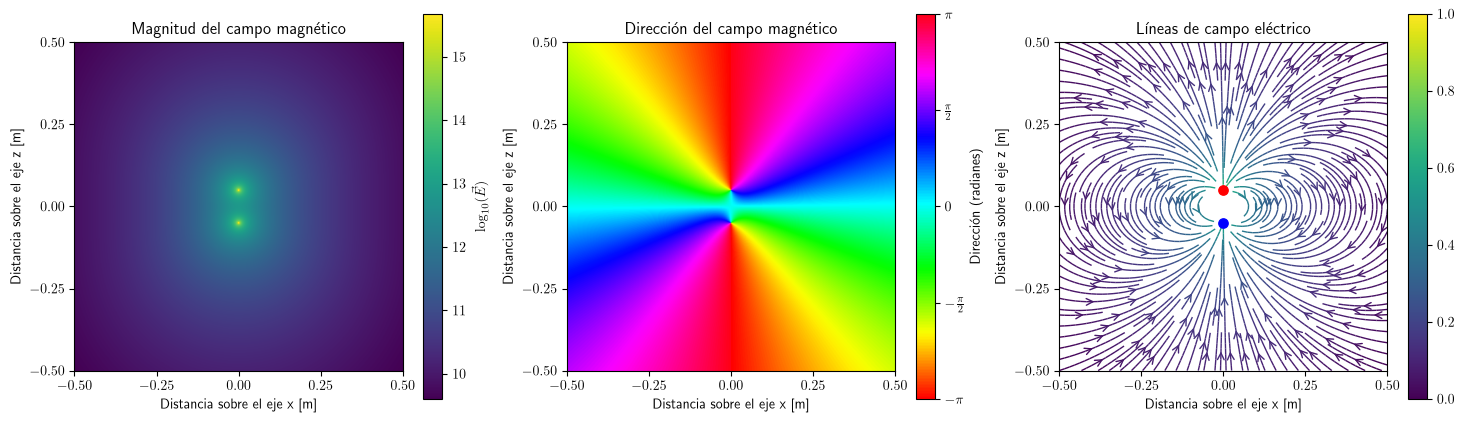

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def potencial_xz(x,z):
    epsilon_0 = 8.8541878128e-12
    r1 = np.sqrt(x**2 + (z-0.05)**2)
    r2 = np.sqrt(x**2 + (z+0.05)**2)
    r1[r1==0] = 1e-10
    r2[r2==0] = 1e-10
    return (1/(4*np.pi*epsilon_0)*(1/r1-1/r2))

def diferencia_central_x(f,x,z,h):
    return (f(x+(h/2),z)-f(x-(h/2),z))/h
def diferencia_central_z(f,x,z,h):
    return (f(x,z+(h/2))-f(x,z-(h/2)))/h
x = np.linspace(-0.5,0.5,500)
z = x
X,Z = np.meshgrid(x,z)

Ex = -diferencia_central_x(potencial_xz,X,Z,0.001)
Ez = -diferencia_central_z(potencial_xz,X,Z,0.001)
E = np.sqrt(Ex**2+Ez**2)
θ = (np.arctan2(Ez,Ex) + 3*np.pi/2)%(2*np.pi)-np.pi

plt.figure(figsize = (18,5))

plt.subplot(131)
plt.imshow(np.log10(E),extent = [-0.5,0.5,-0.5,0.5],origin ="lower", cmap ="viridis")
plt.xlim(-0.5,0.5)
plt.ylim(-0.5,0.5)
plt.xticks([-0.5,-0.25,0,0.25,0.5])
plt.yticks([-0.5,-0.25,0,0.25,0.5])
plt.title("Magnitud del campo magnético")
plt.xlabel("Distancia sobre el eje x [m]")
plt.ylabel("Distancia sobre el eje z [m]")
plt.colorbar(label = r"$\log_{10}(\vec{E})$")

plt.subplot(132)
imagen = plt.imshow(θ,extent = [-0.5,0.5,-0.5,0.5],origin ="lower", cmap ="hsv",vmin=-np.pi,vmax=np.pi, aspect ="equal")
plt.xlim(-0.5,0.5)
plt.ylim(-0.5,0.5)
plt.xticks([-0.5,-0.25,0,0.25,0.5])
plt.yticks([-0.5,-0.25,0,0.25,0.5])
plt.title("Dirección del campo magnético")
plt.xlabel("Distancia sobre el eje x [m]")
plt.ylabel("Distancia sobre el eje z [m]")
barra = plt.colorbar(imagen,ticks = [-np.pi,-np.pi/2,0,np.pi/2,np.pi], label = "Dirección (radianes)")
barra.set_ticklabels([r"$-\pi$", r"$-\frac{\pi}{2}$", r"$0$", r"$\frac{\pi}{2}$", r"$\pi$"])

plt.subplot(1, 3, 3)
imagen2 = plt.streamplot(x, z,Ex, Ez,color=np.log10(E),cmap="viridis",linewidth=1,density=2,arrowsize=1.2,arrowstyle="->")
plt.scatter(0, 0.05, color="red", s=45, zorder=5)
plt.scatter(0, -0.05, color="blue", s=45, zorder=5)

plt.title("Líneas de campo eléctrico")
plt.xlim(-0.5,0.5)
plt.ylim(-0.5,0.5)
plt.xticks([-0.5,-0.25,0,0.25,0.5])
plt.yticks([-0.5,-0.25,0,0.25,0.5])
plt.xlabel("Distancia sobre el eje x [m]")
plt.ylabel("Distancia sobre el eje z [m]")
plt.gca().set_aspect("equal")
plt.colorbar()

plt.show()

### (c)

Ahora supongamos que tenemos una distribución continua de carga sobre un cuadrado de $L\times L$. La densidad de carga en $\mathrm{C/m^2}$ es:

$$
\sigma(x,y)=q_0\sin\left(\frac{2\pi x}{L}\right)
                 \sin\left(\frac{2\pi y}{L}\right).
$$

Calcula y visualiza el campo eléctrico resultante en puntos espaciados a 1 cm en 1 metro cuadrado del plano $xy$ para el caso donde $L=10$ cm. La distribución de carga está centrada en el medio del área visualizada y $q_0=100\,\mathrm{C/m^2}$.

Tendrás que realizar una integral doble sobre $x$ y $y$, luego diferenciar el potencial respecto a la posición para obtener el campo eléctrico. Elige cualquier método de integración que parezca apropiado para las integrales.
EL potencial para una distribución superficial de carga está dada por la siguiente integral:

$$\phi= \frac{1}{4\pi\epsilon_0}\int_{S} \frac{\sigma(x,y)}{|\vec{r}-\vec{r}'|}dA$$

In [6]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt

def gauss_xi_w_i(n,a,b):
    if a > b:
        raise ValueError("Esta función requiere que a sea menor que b ya que sigue la estructura de un intervalo cerrado [a,b].")
    
    raices = sp.special.roots_legendre(n)[0]
    pesos = sp.special.roots_legendre(n)[1]
    xi = (b-a)/2 * raices + 1/2 * (b+a)
    wi = (b-a)/2 * pesos
    return xi, wi
    
def CGauss2D(n,f,a,b,c,d):
    C = 0
    xi,wi = gauss_xi_w_i(n,a,b)
    yj,wj = gauss_xi_w_i(n,c,d)
    
    for i in range(0,n):
        for j in range(0,n):
            C += wi[i]*wj[j]*f(xi[i],yj[j])
    return float(C)

def diferencia_central_x(f,x,y,h):
    return (f(x+(h/2),y)-f(x-(h/2),y))/h
def diferencia_central_y(f,x,y,h):
    return (f(x,y+(h/2))-f(x,y-(h/2)))/h

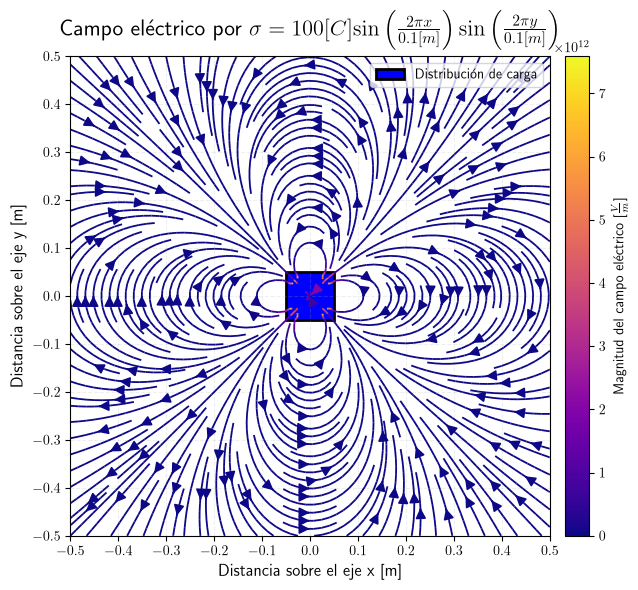

In [7]:
L = 0.1
q0 = 100
epsilon_0 = 8.8541878128e-12


def σ(x,y):
    return q0*np.sin(2*np.pi*x/L)*np.sin(2*np.pi*y/L)

def ϕ(x,y):
    def integrando(u,v):
        r = np.sqrt((x-u)**2+(y-v)**2)
        if r < 1e-10:
            r = 1e-10
        return (1/(4*np.pi*epsilon_0))*σ(u,v)/r
    return CGauss2D(8,integrando,-L/2,L/2,-L/2,L/2)

x = np.linspace(-0.5,0.5,101)
y = x
X,Y = np.meshgrid(x,y)

potencial = np.zeros_like(X)
Ex_1 = np.zeros_like(X)
Ey_1 = np.zeros_like(X)

for i in range(0,X.shape[0]):
    for j in range(0,X.shape[1]):
        x1 = X[i,j]
        y1 = Y[i,j]
        potencial[i,j]= ϕ(x1,y1)
        Ex_1[i,j] = -diferencia_central_x(ϕ,x1,y1,0.01)
        Ey_1[i,j] = -diferencia_central_y(ϕ,x1,y1,0.01)
E1 = np.sqrt(Ex_1**2 + Ey_1**2)

plt.figure(figsize=(8,6))

grafica = plt.streamplot(x,y,Ex_1,Ey_1,color=E1,cmap="plasma",density=2,linewidth=1.3,arrowsize=1.5)
plt.colorbar(grafica.lines,label=r"Magnitud del campo eléctrico [$\frac{V}{m}$]",pad=0.02)
distribucion_carga = plt.Rectangle((-L/2,-L/2),L,L,edgecolor="black",facecolor="blue",lw=2,label="Distribución de carga")
plt.gca().add_patch(distribucion_carga)

plt.title(r"Campo eléctrico por $\sigma = 100[C]\mathrm{sin}\left(\frac{2\pi x}{0.1[m]}\right)\mathrm{sin}\left(\frac{2\pi y}{0.1[m]}\right)$",fontsize=16,pad=15)
plt.xlabel("Distancia sobre el eje x [m]",fontsize=12)
plt.ylabel("Distancia sobre el eje y [m]",fontsize=12)
plt.xlim(-0.5,0.5)
plt.ylim(-0.5,0.5)
plt.xticks(np.arange(-0.5,0.51,0.1))
plt.yticks(np.arange(-0.5,0.51,0.1))
plt.gca().set_aspect("equal",adjustable="box")

plt.grid(linestyle="--",alpha=0.2)
plt.legend()
plt.tight_layout()

plt.show()

---
# 3. Procesamiento de imágenes y STM (valor 4 puntos)

Cuando la luz incide sobre una superficie, la cantidad que cae por unidad de área depende no sólo de la intensidad de la luz, sino también del ángulo de incidencia. Si la luz forma un ángulo $\theta$ con la normal, sólo “ve” una fracción $\cos\theta$ de área, por unidad de área real en la superficie.

Así, la intensidad de la iluminación es $a\cos\theta$, si $a$ es la intensidad bruta de la luz. Esta simple ley física es un elemento central de los gráficos por computadora en 3D. Nos permite calcular cómo incide la luz sobre objetos tridimensionales y, por tanto, cómo se verán cuando se iluminen desde varios ángulos.

Supongamos, por ejemplo, que miramos la Tierra desde arriba y vemos sus montañas. Conocemos la altura de las montañas $w(x,y)$ en función de la posición en el plano, por lo que la ecuación para la superficie de la Tierra es simplemente $z=w(x,y)$, o equivalentemente $w(x,y)-z=0$, y el vector normal $\vec v$ a la superficie está dado por el gradiente de $w(x,y)-z$:

$$
\begin{aligned}
\vec{v} &= \nabla \left[ w(x,y) - z \right] \\[1ex]
&= 
\begin{pmatrix}
\frac{\partial}{\partial x} \\[1ex]
\frac{\partial}{\partial y} \\[1ex]
\frac{\partial}{\partial z}
\end{pmatrix}
\left[ w(x,y) - z \right] \\[1ex]
&= 
\begin{pmatrix}
\frac{\partial w}{\partial x} \\[1ex]
\frac{\partial w}{\partial y} \\[1ex]
-1
\end{pmatrix}
\end{aligned}
$$

Ahora supongamos que tenemos luz entrante representada por un vector $\vec a$ con magnitud igual a la intensidad de la luz. Entonces el producto escalar de los vectores $\vec a$ y $\vec v$ es:

$$
\vec a\cdot\vec v=|\vec a|\,|\vec v|\cos\theta,
$$

donde $\theta$ es el ángulo entre los vectores.

Entonces, la intensidad de la iluminación de la superficie de las montañas es:

$$
\begin{aligned}
I &= \left| \vec{a} \right| \cos \theta \\[1ex]
  &= \frac{\vec{a} \cdot \vec{v}}{\left| \vec{v} \right|} \\[2ex]
  &= \frac{a_x \left( \frac{\partial w}{\partial x} \right) + a_y \left( \frac{\partial w}{\partial y} \right) - a_z}{\sqrt{ \left( \frac{\partial w}{\partial x} \right)^2 + \left( \frac{\partial w}{\partial y} \right)^2 + 1 }} \,.
\end{aligned}
$$

Tomemos un caso simple donde la luz brilla horizontalmente con intensidad unitaria, a lo largo de una línea en un ángulo $\phi$ en sentido contrario a las manecillas del reloj desde el eje este-oeste, de modo que $\vec a=(\cos\phi,\sin\phi,0)$. Entonces nuestra intensidad de iluminación se simplifica a:

$$
I = \frac{\cos\phi \left( \frac{\partial w}{\partial x} \right) + \sin\phi \left( \frac{\partial w}{\partial y} \right)}{\sqrt{ \left( \frac{\partial w}{\partial x} \right)^2 + \left( \frac{\partial w}{\partial y} \right)^2 + 1 }} \,.
$$

Así, si podemos calcular las derivadas de la altura $w(x,y)$ y sabemos $\phi$, entonces podemos calcular la intensidad en cualquier punto.

### (a)

El archivo adjunto `altitudes.txt` contiene la altitud $w(x,y)$ en metros sobre el nivel del mar (o profundidad bajo el nivel del mar) de la superficie de la Tierra, medida en una cuadrícula de puntos $(x,y)$. Escribe un programa que lea este archivo y almacene los datos en una matriz. Luego calcula las derivadas $\frac{\partial w}{\partial x}$ y $ \frac{\partial w}{\partial y}$ en cada punto de la cuadrícula. Explica qué método utilizaste para calcularlos y por qué.

**Hint:** probablemente tendrás que usar más de un método para obtener cada punto de la cuadrícula porque suceden cosas incómodas en los bordes de la misma.

Para calcular las derivadas, necesitarás saber el valor de $h$ y la distancia en metros entre puntos de la cuadrícula, que es de aproximadamente $30\,000$ m en este caso¹.

In [9]:
import numpy as np

with open("data/altitudes.txt","r") as txt:
    datos = []
    for linea in txt:
        fila = [float(numero) for numero in linea.split()]
        datos.append(fila)
w = np.array(datos)

parcialw_x = np.zeros((w.shape[0],w.shape[1]))
parcialw_y = np.zeros((w.shape[0],w.shape[1]))

h = 30000
#Voy a emplear las diferencias hacia atrás y hacia adelante para los bordes.
#Mientras que el resto de datos con diferencias centrales.
for i in range(0,w.shape[0]):
    for j in range(0,w.shape[1]):
        if j == 0:
            parcialw_y[i,j] = (w[i,j+1]-w[i,j])/h
        elif j == w.shape[1]-1:
            parcialw_y[i,j] = (w[i,j]-w[i,j-1])/h
        else:
            parcialw_y[i,j] = (w[i,j+1]-w[i,j-1])/(2*h)

        if i == 0:
            parcialw_x[i,j] = (w[i+1,j]-w[i,j])/h
        elif i == w.shape[0]-1:
            parcialw_x[i,j] = (w[i,j]-w[i-1,j])/h
        else:
            parcialw_x[i,j] = (w[i+1,j]-w[i-1,j])/(2*h)

print("La derivada parcial de w respecto a x en cada punto es:\n",parcialw_x)
print("La derivada parcial de w respecto a y en cada punto es:\n",parcialw_y)


La derivada parcial de w respecto a x en cada punto es:
 [[ 0.004891    0.005186    0.00547167 ...  0.00385367  0.00422067
   0.00458067]
 [ 0.02438683  0.02444717  0.02441683 ...  0.02337717  0.0238115
   0.02418133]
 [ 0.03476033  0.03422017  0.033555   ...  0.03458617  0.03478583
   0.03493867]
 ...
 [-0.00280683 -0.00280083 -0.00279533 ... -0.00281483 -0.00281233
  -0.00281033]
 [-0.00326417 -0.003239   -0.00321217 ... -0.00334017 -0.00331617
  -0.00328967]
 [-0.003727   -0.003699   -0.003672   ... -0.00382    -0.00378833
  -0.00375833]]
La derivada parcial de w respecto a y en cada punto es:
 [[ 4.26666667e-05  3.65000000e-05  2.91666667e-05 ...  9.03333333e-05
   8.10000000e-05  7.56666667e-05]
 [ 3.37666667e-04  3.26833333e-04  3.04333333e-04 ...  4.61000000e-04
   4.44500000e-04  4.35666667e-04]
 [ 1.63333333e-04  6.65000000e-05 -7.51666667e-05 ...  9.66500000e-04
   8.85166667e-04  8.15333333e-04]
 ...
 [-5.33333333e-05 -5.48333333e-05 -5.55000000e-05 ... -5.00000000e-05
  -5.

Utilicé las diferencias centrales en los puntos interiores porque ahí si tengo almenos dos valores de altitud a ambos lados del punto donde calculo la derivada. 

En los bordes de la matriz no se puede utilizar diferencias centrales porque no existen puntos fuera de la cuadrícula. Por esta razón usé diferencias hacia adelante y hacia atrás en el primer y último punto respectivamente.

### (b)

Ahora, usando tus valores para las derivadas, calcula la intensidad para cada punto de la cuadrícula, con $\phi=45^\circ$, y haz un gráfico de densidad de los valores resultantes en el que el brillo de cada punto depende del valor correspondiente de intensidad.

Si lo haces funcionar correctamente, la gráfica debería verse como un mapa en relieve del mundo; deberías poder ver los continentes y las cadenas montañosas en 3D. Algunos problemas comunes pueden ser que el mapa esté al revés o de lado, o que el relieve esté “de adentro hacia afuera”, es decir, que las regiones altas se vean bajas y viceversa. Trabaja con los detalles de tu programa hasta que obtengas un mapa que te parezca adecuado.

**Hint:** ten en cuenta que el valor de la intensidad $I$ de la fórmula anterior puede ser positivo o negativo; oscila entre $+1$ y $-1$. ¿Qué significa una intensidad negativa? Significa que el área en cuestión está en sombras (es decir, que se encuentra en el lado equivocado de la montaña para recibir alguna luz).

Podrías representar esto coloreando esas áreas del mapa completamente de negro, aunque en la práctica obtendrás una imagen más bonita (aunque tal vez menos realista) simplemente usando una gama continua de grises desde $+1$ hasta $-1$.

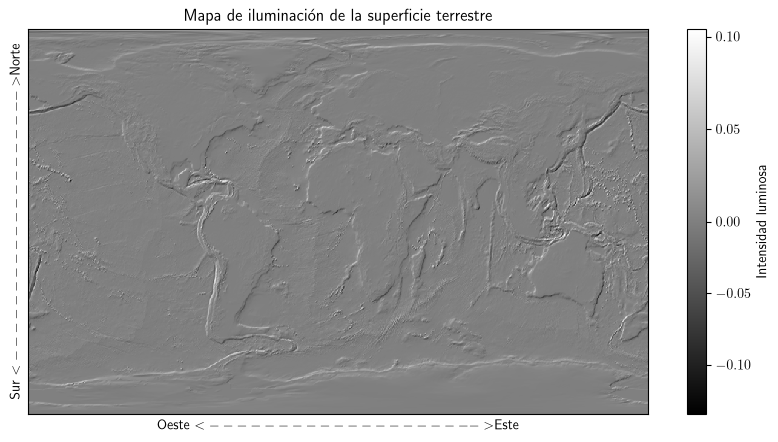

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

I = (np.cos(np.pi/4)*parcialw_x + np.sin(np.pi/4)*parcialw_y)/np.sqrt((parcialw_x)**2+(parcialw_y)**2+1)

limites = colors.TwoSlopeNorm(vmin=np.min(I),vcenter=0,vmax=np.max(I))

plt.figure(figsize=(10,5))
plt.imshow(I, cmap= "gray", origin = "upper",norm = limites, interpolation="nearest", aspect ="auto")

plt.title("Mapa de iluminación de la superficie terrestre")
plt.xticks([])
plt.yticks([])
plt.xlabel(r"Oeste $<-------------------->$Este")
plt.ylabel(r"Sur $<-------------------->$Norte")

plt.colorbar(label="Intensidad luminosa")
plt.show()



# (c)

El otro archivo adjunto llamado `stm.txt` contiene una cuadrícula con valores de mediciones de un microscopio de efecto túnel (scanning tunneling microscope o STM) de la superficie (111) del silicio.

Un microscopio de efecto túnel (STM) es un dispositivo que mide la forma de superficies a nivel atómico siguiendo una punta afilada sobre la superficie y midiendo la corriente de efecto túnel cuántico en función de la posición. El resultado final es una cuadrícula de valores que representan la altura de la superficie en función de la posición y los datos del archivo `stm.txt` contienen precisamente esa rejilla de valores.

Modifica tu programa anterior para visualizar los datos STM y así crear una imagen 3D de cómo se ve la superficie de silicio. El valor de $h$ para las derivadas en este caso es de alrededor de $h=2.5$ (en unidades arbitrarias).

---

¹ En realidad, no es precisamente constante porque estamos representando la Tierra de forma esférica en un mapa plano, pero $h=30\,000$ m nos dará resultados razonables.

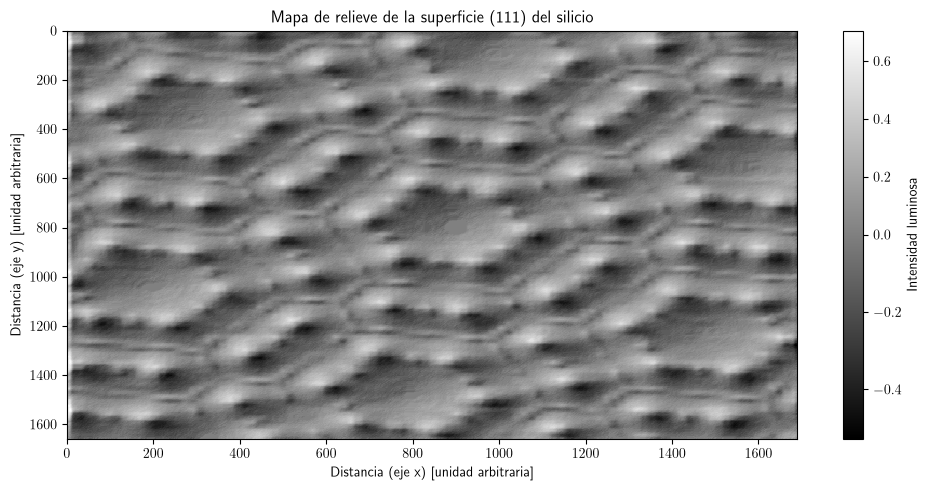

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
with open("data/stm.txt","r") as txt:
    datos = []
    for linea in txt:
        fila = [float(numero) for numero in linea.split()]
        datos.append(fila)
z = np.array(datos)
parcialz_x = np.zeros((z.shape[0],z.shape[1]))
parcialz_y = np.zeros((z.shape[0],z.shape[1]))
h = 2.5
for i in range(0,z.shape[0]):
    for j in range(0,z.shape[1]):
        if j == 0:
            parcialz_y[i,j] = (z[i,j+1]-z[i,j])/h
        elif j == z.shape[1]-1:
            parcialz_y[i,j] = (z[i,j]-z[i,j-1])/h
        else:
            parcialz_y[i,j] = (z[i,j+1]-z[i,j-1])/(2*h)
        if i == 0:
            parcialz_x[i,j] = (z[i+1,j]-z[i,j])/h
        elif i == z.shape[0]-1:
            parcialz_x[i,j] = (z[i,j]-z[i-1,j])/h
        else:
            parcialz_x[i,j] = (z[i+1,j]-z[i-1,j])/(2*h)
I = (np.cos(np.pi/4)*parcialz_x + np.sin(np.pi/4)*parcialz_y)/np.sqrt(parcialz_x**2+parcialz_y**2+1)
limites = colors.TwoSlopeNorm(vmin=np.min(I),vcenter=0,vmax=np.max(I))
plt.figure(figsize=(10,5))
plt.imshow(I,cmap="gray",origin="upper",norm=limites,interpolation="nearest",aspect="auto",extent=[0,z.shape[1]*h,z.shape[0]*h,0])
plt.title("Mapa de relieve de la superficie (111) del silicio")
plt.colorbar(label="Intensidad luminosa")
plt.xlabel("Distancia (eje x) [unidad arbitraria]")
plt.ylabel("Distancia (eje y) [unidad arbitraria]")
plt.tight_layout()
plt.show()

---
## 4. Derivación mediante integración (valor 2 puntos)

Supongamos que tenemos una función $f(z)$ cuyo valor conocemos no solo sobre la recta real, sino también para valores complejos de su argumento. Entonces, podemos calcular las derivadas de dicha función en cualquier punto $z_0$ mediante una integral de contorno, utilizando la fórmula de la derivada de Cauchy:

$$
\left(\frac{d^m f}{dz^m}\right)_{z=z_0}
=\frac{m!}{2\pi i}\oint
\frac{f(z)}{(z-z_0)^{m+1}}\,dz,
$$

donde la integral se realiza en sentido antihorario a lo largo de cualquier contorno en el plano complejo que rodee al punto $z_0$, pero que no contiene polos de $f(z)$.

Dado que la integración numérica es considerablemente más sencilla y precisa que la diferenciación numérica, esta fórmula nos proporciona un método para calcular derivadas con gran precisión (especialmente de orden superior), transformándolas en integrales.

Por ejemplo, supongamos que queremos calcular las derivadas de $f(z)$ en $z=0$. Aplicando la fórmula de Cauchy y utilizando la regla del trapecio para calcular la integral a lo largo de un contorno circular centrado en el origen con radio 1. La regla del trapecio será ligeramente distinta a la versión a la que hemos trabajado, ya que el valor del intervalo $h$ es ahora un número complejo; además, este no permanece constante entre los distintos segmentos de la integral: su módulo sí se mantiene constante, pero su argumento varía de un segmento a otro.

Dividiendo la integral en $N$ segmentos, con puntos muestra $z_k$ distribuidos uniformemente a lo largo del contorno circular, en las posiciones

$$
z_k=e^{i2\pi k/N},\qquad k=0,\ldots,N.
$$

Entonces, la distancia entre puntos de muestreo consecutivos es:

$$
h_k=z_{k+1}-z_k
=e^{i2\pi(k+1)/N}-e^{i2\pi k/N}.
$$

Y, definiendo $g(z)=f(z)/z^{m+1}$ con notación abreviada para el integrando, la aproximación de la integral mediante la regla del trapecio sería:

$$
\begin{aligned}
\oint g(z)\,dz
&\simeq\sum_{k=0}^{N-1}
\frac{1}{2}\left[g(z_{k+1})+g(z_k)\right]
\left[e^{i2\pi(k+1)/N}-e^{i2\pi k/N}\right]\\
&=\frac{1}{2}\Bigg[
\sum_{k=0}^{N-1}g(z_{k+1})e^{i2\pi(k+1)/N}
-\sum_{k=0}^{N-1}g(z_k)e^{i2\pi k/N}\\
&\qquad-\sum_{k=0}^{N-1}g(z_{k+1})e^{i2\pi k/N}
+\sum_{k=0}^{N-1}g(z_k)e^{i2\pi(k+1)/N}
\Bigg].
\end{aligned}
$$


Si observamos que $z_N=z_0$, las dos primeras sumas dentro de los corchetes se cancelan por completo, y las dos sumas restantes son iguales, salvo por factores de fase triviales; por tanto, toda la expresión se simplifica a:

$$
\begin{aligned}
\oint g(z)\,dz
&\simeq\frac{1}{2}
\left[e^{i2\pi/N}-e^{-i2\pi/N}\right]
\sum_{k=0}^{N-1}g(z_k)e^{i2\pi k/N}\\
&\simeq\frac{2\pi i}{N}
\sum_{k=0}^{N-1}f(z_k)e^{-i2\pi km/N},
\end{aligned}
$$

donde hemos vuelto a utilizar la definición de $g(z)$. Combinando este resultado con la fórmula de Cauchy, obtenemos que:

$$
\boxed{
\left(\frac{d^m f}{dz^m}\right)_{z=0}
\simeq\frac{m!}{N}
\sum_{k=0}^{N-1}f(z_k)e^{-i2\pi km/N}
}
\tag{1}
$$

Escribe un programa para calcular las primeras veinte derivadas de $f(z)=e^{2z}$ en $z=0$ utilizando la ecuación (1) con $N=10000$.

Usa la función `exp` del paquete `cmath`, la cual admite argumentos complejos. También te puede resultar útil la función `factorial` del paquete `math`, que calcula factoriales de argumentos enteros.

Es fácil demostrar que el valor correcto de la $m$-ésima derivada en este caso es $2^m$; por tanto, resulta sencillo comprobar si tu programa funciona correctamente: los resultados deberían ser potencias de dos (2, 4, 8, 16, 32, etc.).

Notarás que, mediante esta técnica, es posible obtener resultados razonablemente precisos para las veinte derivadas de forma rápida. Por otro lado, si utilizas las fórmulas de diferencias estándar para calcular las derivadas, observarás que solo es posible determinar con precisión las tres o cuatro primeras antes de que los errores numéricos se vuelvan tan grandes que los resultados carezcan de utilidad. En este caso, la fórmula de Cauchy proporciona, por consiguiente, mejores resultados.

Por cierto, la suma $\sum_k f(z_k)e^{i2\pi km/N}$ que aparece en la fórmula anterior se denomina transformada discreta de Fourier de los puntos muestra complejos $f(z_k)$. Existe una técnica elegante para evaluar la transformada de Fourier para muchos valores de $m$ de forma simultánea, conocida como transformada rápida de Fourier, la cual puede resultar útil en situaciones en las que la evaluación directa de la fórmula es lenta.


In [15]:
import math as mt
from cmath import exp

def derivada_alrededor_cero(f,m,N):
    if m < 0:
        raise ValueError("Esta función está definida para números enteros no negativos.")
    if not isinstance(m,int) or not isinstance(N,int):
        raise TypeError("Solo admite números enteros no negativos.")
    if N <=0:
        raise ValueError("N debe ser entero positivo.")
    s = 0
    for k in range(0,N):
        z_k = exp(1j*2*mt.pi*k/N)
        s+=f(z_k)*exp(-1j*2*mt.pi*k*m/N)
    return (mt.factorial(m)/N)*s

In [16]:
def funcion_prueba(z):
    return exp(2*z)

In [17]:
print("\t\tDerivadas de f(z) = exp(2z)\n")
print("-"*70)
print("  Orden\t\tResultado numérico\t\tValor exacto")
print("-"*70)
for i in range(1,21):
    
    resultado = derivada_alrededor_cero(funcion_prueba,i,10000)
    print("  ",i,"\t\t",resultado.real,"\t\t",2**i)
print("-"*70)

		Derivadas de f(z) = exp(2z)

----------------------------------------------------------------------
  Orden		Resultado numérico		Valor exacto
----------------------------------------------------------------------
   1 		 1.9999999999999925 		 2
   2 		 3.99999999999999 		 4
   3 		 8.000000000000002 		 8
   4 		 16.000000000000018 		 16
   5 		 32.00000000000003 		 32
   6 		 64.00000000000026 		 64
   7 		 128.00000000000168 		 128
   8 		 255.99999999998712 		 256
   9 		 511.9999999999226 		 512
   10 		 1024.000000000446 		 1024
   11 		 2048.0000000039868 		 2048
   12 		 4095.999999709018 		 4096
   13 		 8191.99999767901 		 8192
   14 		 16383.999969751962 		 16384
   15 		 32767.999499965485 		 32768
   16 		 65535.99608144405 		 65536
   17 		 131071.93379686632 		 131072
   18 		 262142.83101705124 		 262144
   19 		 524273.9928697285 		 524288
   20 		 1048245.9203696527 		 1048576
----------------------------------------------------------------------
